## 1. Load the needed columns and choose a city

In [1]:
# Read the provided CSV and filter to one city.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CITY = 'Miami'
STATE = 'FL'
csv_path = Path('../data/US_Accidents_March23_sampled_500k.csv')
accidents = pd.read_csv(
    csv_path,
    usecols=['City', 'State', 'Source', 'Severity', 'Weather_Condition',
             'Precipitation(in)', 'Visibility(mi)'],
    low_memory=False,
)
city = accidents.loc[(accidents['City'] == CITY) & (accidents['State'] == STATE)].copy()
city['Higher traffic impact'] = city['Severity'].isin([3, 4])

print('Accidents in full CSV:', len(accidents))
print(f'Accidents in {CITY}, {STATE}:', len(city))
print('Accidents by source:')
display(city['Source'].value_counts())
print('Traffic-impact severity counts:')
display(city['Severity'].value_counts().sort_index())

Accidents in full CSV: 500000
Accidents in Miami, FL: 12131
Accidents by source:


Source
Source1    9900
Source2    2182
Source3      49
Name: count, dtype: int64

Traffic-impact severity counts:


Severity
1       10
2    10978
3      995
4      148
Name: count, dtype: int64

## 2. Check missing values before deciding what to drop

In [2]:
# Count blanks in the city subset.
missing = city[['Weather_Condition', 'Precipitation(in)',
                'Visibility(mi)', 'Severity']].isna().sum()
missing_percent = (100 * missing / len(city)).round(1)
missing_table = pd.DataFrame({'Missing rows': missing,
                              'Percent of city rows': missing_percent})
display(missing_table)
assert city['Severity'].notna().all()

,Missing rows,Percent of city rows
Weather_Condition,93,0.8
Precipitation(in),1448,11.9
Visibility(mi),125,1.0
Severity,0,0.0


## 3. See which weather labels appear most often

In [3]:
# Count weather labels and show the four traffic-impact severity ratings.
weather_counts = city['Weather_Condition'].value_counts().head(8)
weather_order = weather_counts.index.tolist()
display(weather_counts.rename('Accident records'))

weather_severity = pd.crosstab(city['Weather_Condition'], city['Severity'])
weather_severity = weather_severity.reindex(index=weather_order,
                                            columns=[1, 2, 3, 4], fill_value=0)
weather_severity.columns = ['Severity 1', 'Severity 2',
                            'Severity 3', 'Severity 4']
weather_severity['Total'] = weather_severity.sum(axis=1)
weather_severity['Percent severity 3–4'] = (
    100 * (weather_severity['Severity 3'] + weather_severity['Severity 4'])
    / weather_severity['Total']
).round(1)
display(weather_severity)
assert weather_severity['Total'].sum() == weather_counts.sum()

Weather_Condition
Fair                       3867
Mostly Cloudy              2955
Partly Cloudy              1960
Cloudy                     1000
Light Rain                  532
Clear                       388
Scattered Clouds            302
Thunder in the Vicinity     156
Name: Accident records, dtype: int64

,Severity 1,Severity 2,Severity 3,Severity 4,Total,Percent severity 3–4
Weather_Condition,,,,,,
Fair,2,3677,160,28,3867,4.9
Mostly Cloudy,3,2702,222,28,2955,8.5
Partly Cloudy,1,1754,173,32,1960,10.5
Cloudy,2,949,41,8,1000,4.9
Light Rain,2,474,49,7,532,10.5
Clear,0,221,149,18,388,43.0
Scattered Clouds,0,190,103,9,302,37.1
Thunder in the Vicinity,0,149,7,0,156,4.5


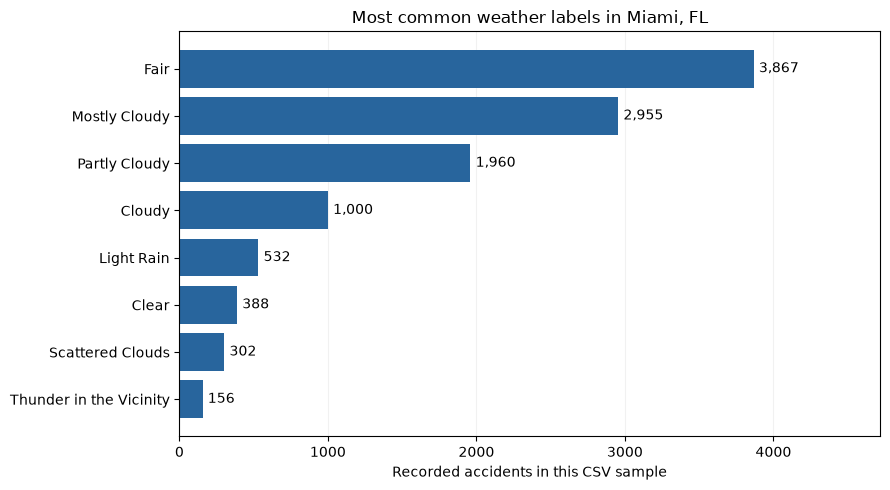

Saved: ..\charts\miami_weather_counts.png


In [4]:
# Save a simple count chart for the team.
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(weather_order, weather_counts.to_numpy(), color='#28659d')
ax.invert_yaxis()
ax.set_xlim(0, weather_counts.max() * 1.22)
ax.set_xlabel('Recorded accidents in this CSV sample')
ax.set_title(f'Most common weather labels in {CITY}, {STATE}')
ax.grid(axis='x', alpha=0.17)
ax.set_axisbelow(True)
for bar, count in zip(bars, weather_counts):
    ax.text(bar.get_width() + 35, bar.get_y() + bar.get_height()/2,
            f'{count:,}', va='center')
fig.tight_layout()
weather_chart = Path('../charts/miami_weather_counts.png')
weather_chart.parent.mkdir(exist_ok=True)
fig.savefig(weather_chart, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', weather_chart)

## 4. Group the numeric measurements

In [5]:
# Keep missing readings as their own category.
precip = city['Precipitation(in)']
city['Precipitation group'] = 'Missing'
city.loc[precip.eq(0), 'Precipitation group'] = '0 inches'
city.loc[precip.gt(0), 'Precipitation group'] = 'Above 0 inches'

visibility = city['Visibility(mi)']
city['Visibility group'] = 'Missing'
city.loc[visibility.lt(5), 'Visibility group'] = 'Under 5 miles'
city.loc[visibility.ge(5) & visibility.lt(10), 'Visibility group'] = '5 to <10 miles'
city.loc[visibility.ge(10), 'Visibility group'] = '10+ miles'

precip_order = ['0 inches', 'Above 0 inches', 'Missing']
visibility_order = ['Under 5 miles', '5 to <10 miles', '10+ miles', 'Missing']

# For each source and group, count accidents and the higher-impact subset.
def impact_table(column, order):
    table = city.groupby([column, 'Source'])['Higher traffic impact'].agg(
        accidents='size', severity_3_or_4='sum'
    ).reset_index()
    table['percent_3_or_4'] = (
        100 * table['severity_3_or_4'] / table['accidents']
    ).round(1)
    table[column] = pd.Categorical(table[column], categories=order, ordered=True)
    return table.sort_values([column, 'Source'])

precip_table = impact_table('Precipitation group', precip_order)
visibility_table = impact_table('Visibility group', visibility_order)
print('Precipitation and traffic impact:')
display(precip_table)
print('Visibility and traffic impact:')
display(visibility_table)

assert precip_table['accidents'].sum() == len(city)
assert visibility_table['accidents'].sum() == len(city)

Precipitation and traffic impact:


,Precipitation group,Source,accidents,severity_3_or_4,percent_3_or_4
0,0 inches,Source1,8794,98,1.1
1,0 inches,Source2,1033,414,40.1
2,0 inches,Source3,19,8,42.1
3,Above 0 inches,Source1,645,22,3.4
4,Above 0 inches,Source2,185,79,42.7
5,Above 0 inches,Source3,7,4,57.1
6,Missing,Source1,461,144,31.2
7,Missing,Source2,964,363,37.7
8,Missing,Source3,23,11,47.8


Visibility and traffic impact:


,Visibility group,Source,accidents,severity_3_or_4,percent_3_or_4
8,Under 5 miles,Source1,238,9,3.8
9,Under 5 miles,Source2,53,18,34.0
10,Under 5 miles,Source3,3,2,66.7
3,5 to <10 miles,Source1,293,10,3.4
4,5 to <10 miles,Source2,94,30,31.9
5,5 to <10 miles,Source3,3,0,0.0
0,10+ miles,Source1,9256,244,2.6
1,10+ miles,Source2,2023,803,39.7
2,10+ miles,Source3,43,21,48.8
6,Missing,Source1,113,1,0.9


## 5. Compare within each accident data source


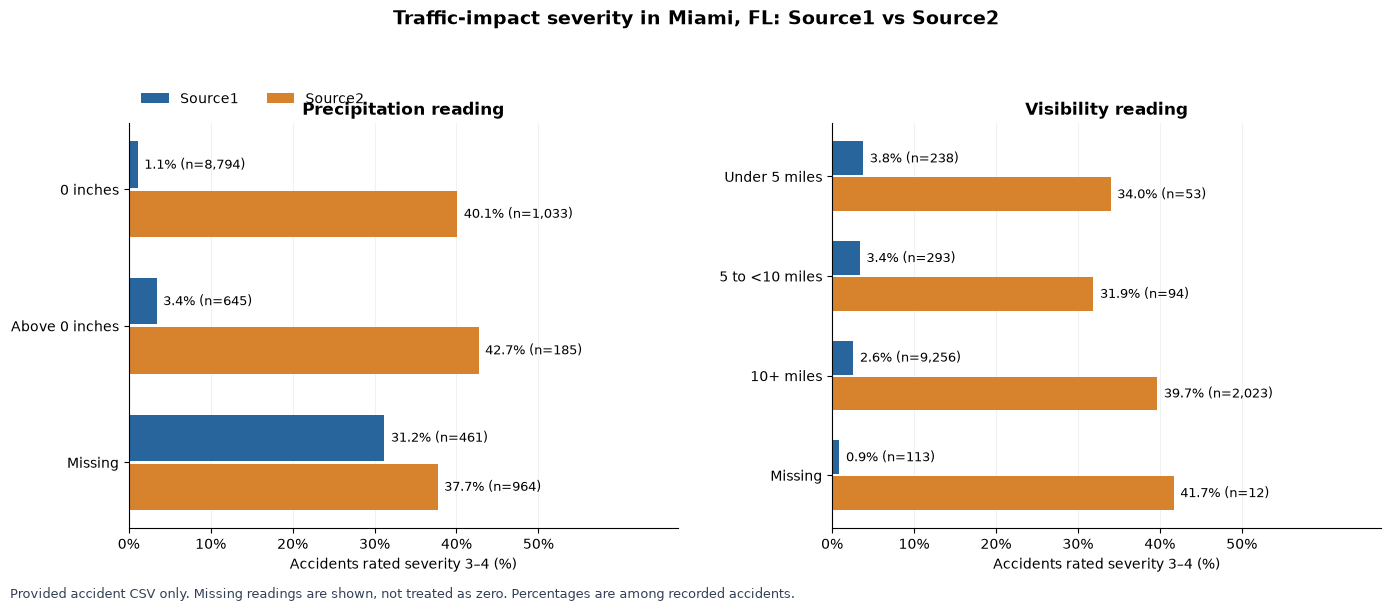

Saved: ..\charts\miami_precip_visibility_severity.png


In [6]:
# Two panels show the two measurements on the same percent scale.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
source_colors = {'Source1': '#28659d', 'Source2': '#d7832e'}

def draw_panel(ax, table, group_column, order, title):
    positions = np.arange(len(order))
    for source, offset in [('Source1', -0.18), ('Source2', 0.18)]:
        rows = (table.loc[table['Source'] == source]
                .set_index(group_column).reindex(order))
        bars = ax.barh(positions + offset, rows['percent_3_or_4'],
                       height=0.34, label=source, color=source_colors[source])
        for bar, row in zip(bars, rows.itertuples()):
            ax.text(bar.get_width() + 0.8,
                    bar.get_y() + bar.get_height()/2,
                    f'{row.percent_3_or_4:.1f}% (n={row.accidents:,})',
                    va='center', fontsize=9)
    ax.set_yticks(positions, labels=order)
    ax.invert_yaxis()
    ax.set_xlim(0, 67)
    ax.set_xticks([0, 10, 20, 30, 40, 50],
                  labels=['0%', '10%', '20%', '30%', '40%', '50%'])
    ax.set_title(title, fontsize=12, weight='bold')
    ax.set_xlabel('Accidents rated severity 3–4 (%)')
    ax.grid(axis='x', alpha=0.17)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

draw_panel(axes[0], precip_table, 'Precipitation group', precip_order,
           'Precipitation reading')
draw_panel(axes[1], visibility_table, 'Visibility group', visibility_order,
           'Visibility reading')
axes[0].legend(loc='lower left', bbox_to_anchor=(0, 1.01),
               ncol=2, frameon=False)
fig.suptitle(f'Traffic-impact severity in {CITY}, {STATE}: Source1 vs Source2',
             fontsize=14, weight='bold', y=1.05)
fig.text(0.01, -0.02,
         'Provided accident CSV only. Missing readings are shown, not treated as zero. Percentages are among recorded accidents.',
         fontsize=9, color='#334155')
fig.tight_layout(w_pad=3)
impact_chart = Path('../charts/miami_precip_visibility_severity.png')
fig.savefig(impact_chart, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', impact_chart)